In [21]:
# relevant import

In [56]:
import importlib
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)



<module 'Optimization' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\Optimization.py'>

In [23]:
import matplotlib.pyplot as plt
import torch
import numpy as np

In [24]:
# mu_list = [np.array([-5, 4]),
#            np.array([5, -4]),
#            np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
#            ]
#
# point_l = [[int(p[1]), int(p[0])] for p in mu_list]
#
# mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]
#
# # Convert Sigma_list to 3D covariance matrices
# Sigma_list = [
#     torch.tensor([[0.5,0.25],[0.12,0.2]], dtype=torch.float64)
# ] * len(mu_list)
#
# # Mixture weights
# alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# # Generate samples
# device = 'cpu'  # Change to 'cuda' if using a GPU
# # X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )
#
#
# mog_means = [
#     torch.tensor([5.0], dtype=torch.float64),
#     # torch.tensor([-5.0], dtype=torch.float64),
#
# ]
# mog_variances = [torch.tensor([.14], dtype=torch.float64),
#      # torch.tensor([.25], dtype=torch.float64),
#      ]
# weights = torch.tensor([1.,
#                         # .5
#                         ], dtype=torch.float64)
#

# Means (3D vectors)
mu_list = [
    torch.tensor([-5.0, -4.0, 3.0], dtype=torch.float64), # First component
torch.tensor([1.0, 3.5, 4.5], dtype=torch.float64), # Second component
 torch.tensor([3.0, 1.5, 8.5], dtype=torch.float64), # Second component
 torch.tensor([5.0, 4.0, 5.0], dtype=torch.float64), # Second component
 torch.tensor([7.0, -1.0, -8.0], dtype=torch.float64) # Second component
]

# Covariance matrices (3x3)
Sigma_list = [
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, .5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
]

# Mixture weights (probability of choosing each component)
alpha = torch.tensor([1., 1.,1.,1.,1.], dtype=torch.float64)*1/len(Sigma_list)

# Means (3D vectors)
mog_means = [
 torch.tensor([4., 5.001], dtype=torch.float64),# First component
 # torch.tensor([4.1, 5.1], dtype=torch.float64),
]

# Covariance matrices (3x3)
mog_variances = [
    torch.tensor([[ .45, 0.0], [0.0, 0.3]], dtype=torch.float64),
]

# Mixture weights (probability of choosing each component)
weights = torch.tensor([1.], dtype=torch.float64)


In [25]:
# @title
if torch.cuda.is_available():
    device = 'cuda:0'
    print('Using gpu')
else:
    device = 'cpu'
    print('Using cpu.')

Using cpu.


In [26]:
X = dist_utils.generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

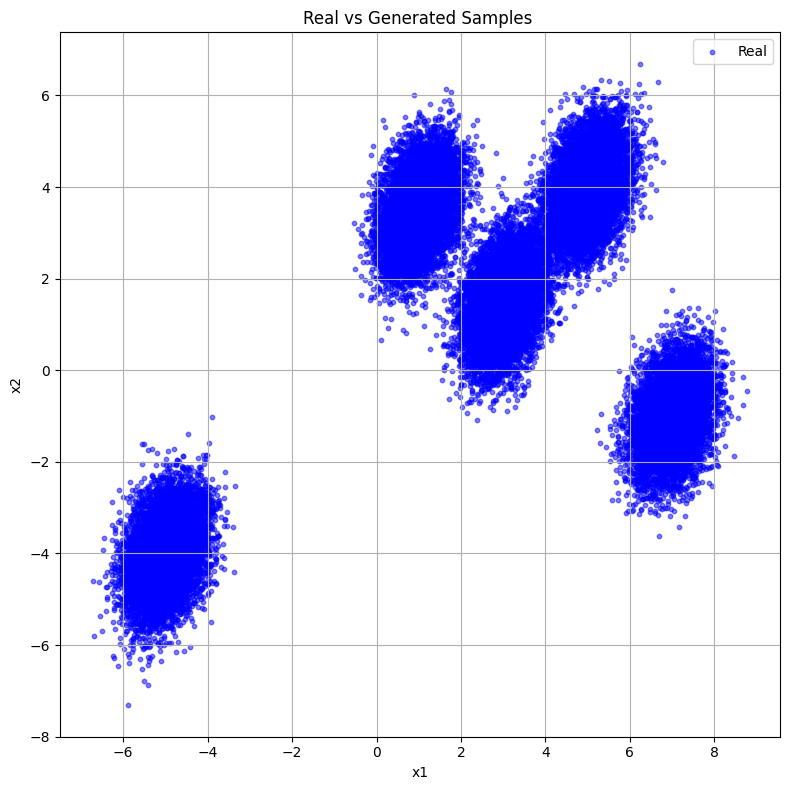

In [27]:
plt.figure(figsize=(8, 8))
plt.scatter(X[:, 0], X[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## LGD

In [28]:
# better version
# init a model, train
nfeatures= X.shape[1]
condition_on=mu_list[0].shape[0]-mog_means[0].shape[0]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=condition_on)
losses = model_cond.train_model(X, nepochs=50, batch_size=3*2048,condition_on=condition_on)

loss: 0.140847: 100%|██████████| 50/50 [01:29<00:00,  1.79s/it]


In [29]:
# init a model, train
X_for_cond_only=X[:,:model_cond.condition_on]
nfeatures= X_for_cond_only.shape[1]
model_uncond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=False,)
losses = model_uncond.train_model(X_for_cond_only, nepochs=50, batch_size=3*2048,condition_on=condition_on)

loss: 0.436610: 100%|██████████| 50/50 [01:25<00:00,  1.72s/it]


### with normal diffusion prediction

In [30]:
x_optim = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 78 | pred_x0_model: 1.695| pred_x0: 1.235| mean_loss: 0.075:  21%|██        | 21/99 [01:28<05:29,  4.22s/it] 


KeyboardInterrupt: 

In [31]:
x_optim = Optimization.optimize_DPS(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=500, loss="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0: tensor([[5.7881]], grad_fn=<AddBackward0>)| mean_loss: 0.341: 100%|██████████| 99/99 [04:18<00:00,  2.61s/it] 
C:\Users\orine\PycharmProjects\finalThesis\dist_utils.py:406: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4416.)
  exponent = -0.5 * diff.T @ Sigma_22_inv @ diff


tensor([[5.7867]])


100%|██████████| 7/7 [00:00<00:00, 22.72it/s]

tensor(0.5490, dtype=torch.float64)


    ### with CM prediction

In [39]:
B, C = X.shape
nfeatures = C - condition_on

Cos_model = ConsistencyModel(nfeatures=nfeatures, condition_on=condition_on, nunits=128)
Cos_model.train_model(X=X, nepochs= 150,batch_size=256, device= "cpu", condition=condition_on)

loss: 0.001096, mu: 0.9993: 100%|██████████| 150/150 [17:46<00:00,  7.11s/it]


In [48]:
x_optim = Optimization.optimize_LGD(model_uncond, Cos_model, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD",CM=True)
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0_model: 0.777| pred_x0: 0.753| mean_loss: 0.263: 100%|██████████| 99/99 [01:15<00:00,  1.31it/s]  


tensor([[0.6891]])


100%|██████████| 7/7 [00:00<00:00, 76.86it/s]

tensor(0.9936, dtype=torch.float64)


In [47]:
x_optim = Optimization.optimize_DPS(model_uncond, Cos_model, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD",CM=True)
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0: tensor([[1.0466]], grad_fn=<AddBackward0>)| mean_loss: 0.338: 100%|██████████| 99/99 [00:17<00:00,  5.63it/s] 


tensor([[1.0465]])


100%|██████████| 7/7 [00:00<00:00, 112.07it/s]

tensor(0.8789, dtype=torch.float64)


## D-FLOW

In [49]:
input_dim = mog_means[0].shape[0]
y_dim = mu_list[0].shape[0] - input_dim
hidden_dim = 256
depth = 4


In [50]:

vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=1024, X=X, nepochs=50)


loss: 1.577834: 100%|██████████| 50/50 [04:42<00:00,  5.65s/it]


In [51]:
first_column_x=X[:,y_dim].reshape(-1,1)#print()
input_dim = first_column_x.shape[1]
vf_X = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=0,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_X.train_FM(lr=0.001, batch_size=1024, X=first_column_x, nepochs=50)


loss: 4.620208: 100%|██████████| 50/50 [03:50<00:00,  4.62s/it]


### with loss of samples

In [52]:
x_optim,loss= Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100,FLAG=True,n_sample=500,loss_method="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)


x_0: [[-0.01139854]] | x_1: tensor([[1.2678]], grad_fn=<SelectBackward0>) | loss: 0.5468713416224493
x_0: [[0.98860145]] | x_1: tensor([[4.1364]], grad_fn=<SelectBackward0>) | loss: 0.21259676294269392
x_0: [[1.3429152]] | x_1: tensor([[4.5668]], grad_fn=<SelectBackward0>) | loss: 0.05912169499247932
x_0: [[1.5591124]] | x_1: tensor([[4.7969]], grad_fn=<SelectBackward0>) | loss: 0.018037287772004973
x_0: [[1.6551112]] | x_1: tensor([[4.8938]], grad_fn=<SelectBackward0>) | loss: 0.04655110535671758
x_0: [[1.5621216]] | x_1: tensor([[4.7999]], grad_fn=<SelectBackward0>) | loss: 0.02653591001497535
x_0: [[1.5594133]] | x_1: tensor([[4.7972]], grad_fn=<SelectBackward0>) | loss: 0.02815452094326787
x_0: [[1.5591125]] | x_1: tensor([[4.7969]], grad_fn=<SelectBackward0>) | loss: 0.043797994811789476
x_0: [[1.5591124]] | x_1: tensor([[4.7969]], grad_fn=<SelectBackward0>) | loss: 0.043569735067449766
x_0: [[1.5591124]] | x_1: tensor([[4.7969]], grad_fn=<SelectBackward0>) | loss: 0.0329883407078

### with KL loss

In [57]:
x_optim,loss= Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100,FLAG=True,n_sample=50,loss_method="KL")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)


x_0: [[0.8093252]] | x_1: tensor([[3.8740]], grad_fn=<SelectBackward0>) | loss: 0.07366317510604858
x_0: [[1.5714041]] | x_1: tensor([[4.8094]], grad_fn=<SelectBackward0>) | loss: -0.006674350704997778
x_0: [[1.5759228]] | x_1: tensor([[4.8140]], grad_fn=<SelectBackward0>) | loss: -0.003814804134890437
x_0: [[1.5714093]] | x_1: tensor([[4.8094]], grad_fn=<SelectBackward0>) | loss: -0.00146110774949193
x_0: [[1.5714046]] | x_1: tensor([[4.8094]], grad_fn=<SelectBackward0>) | loss: -0.011728359386324883
tensor([[4.8094]], grad_fn=<SelectBackward0>)


  0%|          | 0/7 [00:00<?, ?it/s]


RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.